In [3]:
"""
================================================================================
 AMEX CAMPUS CHALLENGE 2026 — BENEFIT UTILISATION MODEL
 Phase 0 (Benefit Registry) + Phase 1 (40,000 Synthetic Customers)
================================================================================

 WHAT THIS SCRIPT DOES
 ---------------------
 Generates one Excel workbook (5 sheets) that becomes the foundation of the
 utilisation-gap model:

   Sheet 1  benefit_registry   -> the 16 benefits + face values (Phase 0)
   Sheet 2  customers          -> 40,000 synthetic cardholders
   Sheet 3  transactions       -> ~2.1M spend records (RBI-calibrated)
   Sheet 4  redemptions        -> who actually used which benefit
   Sheet 5  gap_summary        -> per-customer gross & addressable gap

 IMPORTANT: all "value" numbers are PERCEIVED VALUE TO THE CUSTOMER
 (from the Amex ₹4.5L calculator), NOT cost-to-company. Cost-to-company
 is a later phase (wholesale_factor / cost_class).

 CALIBRATION KNOBS YOU WILL EDIT are in clearly tagged blocks:
   [KNOB-1] benefit face values          -> BENEFIT_REGISTRY
   [KNOB-2] per-benefit utilisation rates -> UTILISATION_PARAMS
   [KNOB-3] spend tiers / city weights    -> CUSTOMER_PARAMS
================================================================================
"""

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# [SETUP] Reproducibility — same seed = same 40,000 customers every run.
# Change the seed if you want a fresh synthetic population.
# --------------------------------------------------------------------------
SEED = 2026
rng = np.random.default_rng(SEED)

N_CUSTOMERS = 40_000
MONTHS = 12
OUTPUT_FILE = "amex_benefit_utilisation.xlsx"
TXN_FILE = "amex_transactions.csv"   # transactions overflow Excel's row limit


# ==========================================================================
# [KNOB-1]  PHASE 0 — BENEFIT REGISTRY
# --------------------------------------------------------------------------
# The 16-row mapping table we locked. Edit face_value_inr to re-tune.
# cost_class drives later ranking logic (not the gap math):
#   zero_marginal | partner_funded | spend_linked | variable | non_monetary
# cap = max units/year (used to convert "units used" -> utilisation %).
# ==========================================================================
BENEFIT_REGISTRY = [
    # benefit_id, name, category, face_value_inr, cap, cost_class, source_note
    ("B01", "International Lounge (unlimited)", "Travel",     38979, 12, "variable",      "Calculator: Priority Pass membership"),
    ("B02", "Domestic Lounge (8/yr)",          "Travel",     12000, 8,  "variable",      "Calculator: Partner Lounges"),
    ("B03", "Travel Insurance (<=1Cr)",        "Travel",     8000,  1,  "zero_marginal", "Estimated: ~4 trips x 2000"),
    ("B04", "Zero Forex Markup",               "Travel",     15000, 1,  "spend_linked",  "Estimated: 3.5% on ~4.3L overseas"),
    ("B05", "Airport Transfers",               "Travel",     6000,  4,  "variable",      "Estimated: 4 rides x 1500"),
    ("B06", "Luxury Hotels + Status (agg)",    "Hotel",      84611, 3,  "zero_marginal", "FHR 44300 + Hotel Collection 28311 + Taj Epicure 12000"),
    ("B07", "Golf Access",                     "Lifestyle",  16000, 8,  "variable",      "Calculator: Domestic Golf"),
    ("B08", "Golf Lessons",                    "Lifestyle",  12000, 8,  "variable",      "Calculator: Golf Lessons"),
    ("B09", "Dining Experiences",              "Lifestyle",  6000,  4,  "spend_linked",  "Calculator: Dining Reimagined"),
    ("B10", "Concierge 24/7",                  "Lifestyle",  5000,  12, "zero_marginal", "Estimated: premium concierge membership"),
    ("B11", "Event Pre-sale Access",           "Lifestyle",  5000,  10, "partner_funded","Calculator: Movie Benefit proxy"),
    ("B12", "Purchase Protection",             "Protection", 3000,  1,  "zero_marginal", "Calculator: direct"),
    ("B13", "Extended Warranty",               "Protection", 3000,  1,  "zero_marginal", "Estimated: mirrors purchase protection"),
    ("B14", "Air Accident Cover",              "Protection", 5000,  1,  "zero_marginal", "Calculator: direct"),
    ("B15", "Fraud Protection + Replacement",  "Protection", 0,     1,  "non_monetary",  "Baseline, no face value"),
    ("B16", "Digital Features (5 items)",      "Digital",    0,     1,  "non_monetary",  "Engagement, no face value"),
]

registry_df = pd.DataFrame(
    BENEFIT_REGISTRY,
    columns=["benefit_id", "name", "category", "face_value_inr", "cap",
             "cost_class", "source_note"],
)

TOTAL_FACE_VALUE = int(registry_df["face_value_inr"].sum())  # = 219,590


# ==========================================================================
# [KNOB-2]  UTILISATION PARAMETERS  (the most important calibration table)
# --------------------------------------------------------------------------
# For each benefit:
#   adoption   = fraction of customers who use it AT ALL
#   avg_util   = average utilisation % AMONG those who use it (0-1)
# These are the defaults you said you'd adjust after seeing survey data.
# Non-monetary benefits (B15,B16) are left at 0 — they carry no gap.
# ==========================================================================
UTILISATION_PARAMS = {
    # benefit_id : (adoption_rate, avg_util_among_users)
    "B01": (0.55, 0.60),
    "B02": (0.65, 0.50),
    "B03": (0.10, 1.00),
    "B04": (0.40, 0.70),
    "B05": (0.20, 0.50),
    "B06": (0.25, 0.35),
    "B07": (0.12, 0.40),
    "B08": (0.08, 0.30),
    "B09": (0.35, 0.45),
    "B10": (0.15, 0.30),
    "B11": (0.20, 0.40),
    "B12": (0.05, 1.00),
    "B13": (0.03, 1.00),
    "B14": (0.02, 1.00),
    "B15": (0.00, 0.00),   # non-monetary
    "B16": (0.00, 0.00),   # non-monetary
}


# ==========================================================================
# [KNOB-3]  CUSTOMER POPULATION PARAMETERS
# --------------------------------------------------------------------------
# City weights: top-6 metros only (per slide 4).
# Spend tiers: annual CARD spend (not household income). Mean ~15-17L.
# ==========================================================================
CITY_WEIGHTS = {
    "Mumbai": 0.25, "Delhi": 0.25, "Bangalore": 0.20,
    "Hyderabad": 0.12, "Chennai": 0.10, "Pune": 0.08,
}

# Cities where golf is realistically accessible (boosts B07/B08 usage).
GOLF_CITIES = {"Delhi", "Mumbai", "Bangalore"}

# Spend tiers: (share_of_population, min_spend, max_spend)
SPEND_TIERS = [
    (0.40, 800_000, 1_500_000),    # moderate
    (0.35, 1_500_000, 2_500_000),  # heavy
    (0.25, 2_500_000, 4_500_000),  # ultra
]

# MCC (merchant category) mix for a premium cardholder.
MCC_WEIGHTS = {
    "travel": 0.20, "dining": 0.18, "retail": 0.22, "grocery": 0.12,
    "fuel": 0.08, "entertainment": 0.08, "utilities": 0.07, "other": 0.05,
}

CHANNEL_WEIGHTS = {"online": 0.60, "pos": 0.35, "international": 0.05}


# ==========================================================================
# STEP 1 — GENERATE CUSTOMERS (Sheet 2)
# ==========================================================================
def generate_customers():
    print("[1/4] Generating 40,000 customers...")

    ids = [f"C{str(i).zfill(5)}" for i in range(1, N_CUSTOMERS + 1)]

    # --- City assignment (weighted) ---
    cities = rng.choice(list(CITY_WEIGHTS.keys()),
                        size=N_CUSTOMERS,
                        p=list(CITY_WEIGHTS.values()))

    # --- Tenure: 6-120 months, right-skewed (most customers are newer) ---
    tenure = np.clip(rng.gamma(shape=2.0, scale=18, size=N_CUSTOMERS), 6, 120).astype(int)

    # --- Annual spend: assign a tier, then sample within it ---
    tier_shares = [t[0] for t in SPEND_TIERS]
    tier_idx = rng.choice(len(SPEND_TIERS), size=N_CUSTOMERS, p=tier_shares)
    annual_spend = np.array([
        rng.integers(SPEND_TIERS[t][1], SPEND_TIERS[t][2]) for t in tier_idx
    ])

    # --- Age: 28-60, centred ~38 ---
    age = np.clip(rng.normal(38, 7, N_CUSTOMERS), 28, 60).astype(int)

    # --- Segment: derived from spend tier ---
    segment = np.select(
        [tier_idx == 0, tier_idx == 1, tier_idx == 2],
        ["Silver", "Gold", "Platinum"],
    )

    df = pd.DataFrame({
        "customer_id": ids,
        "city": cities,
        "tenure_months": tenure,
        "annual_spend": annual_spend,
        "age": age,
        "segment": segment,
    })
    return df


# ==========================================================================
# STEP 2 — GENERATE TRANSACTIONS (Sheet 3)
# --------------------------------------------------------------------------
# Anchored to RBI's 4.51 txn/card/month. Each customer's transactions
# sum (approximately) to their annual_spend. MCC mix reflects premium use.
# ==========================================================================
def generate_transactions(customers):
    print("[2/4] Generating transactions (~2.1M rows, this is the slow step)...")

    all_rows = []
    mcc_keys = list(MCC_WEIGHTS.keys())
    mcc_probs = list(MCC_WEIGHTS.values())
    ch_keys = list(CHANNEL_WEIGHTS.keys())
    ch_probs = list(CHANNEL_WEIGHTS.values())

    for _, cust in customers.iterrows():
        # Transaction count: ~4.5/month with variance (Poisson).
        n_txn = rng.poisson(4.5 * MONTHS)
        n_txn = max(n_txn, 12)  # floor so nobody has too few

        # Split annual_spend across n_txn using a Dirichlet -> realistic
        # skew (a few big-ticket buys, many small ones).
        weights = rng.dirichlet(np.ones(n_txn) * 0.7)
        amounts = (weights * cust["annual_spend"]).round(0).astype(int)

        days = rng.integers(0, 365, size=n_txn)
        mccs = rng.choice(mcc_keys, size=n_txn, p=mcc_probs)
        channels = rng.choice(ch_keys, size=n_txn, p=ch_probs)

        for k in range(n_txn):
            all_rows.append((
                cust["customer_id"],
                int(days[k]),          # day offset 0-364; convert to date if needed
                int(amounts[k]),
                mccs[k],
                channels[k],
            ))

    df = pd.DataFrame(all_rows,
                      columns=["customer_id", "day_of_year", "amount",
                               "mcc_category", "channel"])
    return df


# ==========================================================================
# STEP 3 — GENERATE REDEMPTIONS (Sheet 4)
# --------------------------------------------------------------------------
# The behavioural core. A customer's benefit use CORRELATES with their
# transaction behaviour — not random. Rules:
#   - high travel-MCC spend -> more lounge / hotel / forex / transfer use
#   - golf cities           -> more golf use
#   - higher tenure         -> slightly higher adoption (discovery effect)
#   - NOISE injected so Phase-3 ML can't trivially recover the rule
#     (this is the circularity guard we discussed).
# ==========================================================================
def generate_redemptions(customers, transactions):
    print("[3/4] Generating redemptions (behaviour-linked)...")

    # Pre-compute each customer's travel-spend share (drives travel benefits).
    travel_share = (
        transactions[transactions["mcc_category"] == "travel"]
        .groupby("customer_id")["amount"].sum()
        / transactions.groupby("customer_id")["amount"].sum()
    ).fillna(0)

    cap_lookup = dict(zip(registry_df["benefit_id"], registry_df["cap"]))

    # Which benefits are travel-driven vs neutral.
    TRAVEL_DRIVEN = {"B01", "B02", "B04", "B05", "B06"}
    GOLF_BENEFITS = {"B07", "B08"}

    rows = []
    for _, cust in customers.iterrows():
        cid = cust["customer_id"]
        t_share = travel_share.get(cid, 0.0)
        tenure_boost = min(cust["tenure_months"] / 120, 1.0) * 0.15  # up to +15%
        in_golf_city = cust["city"] in GOLF_CITIES

        for bid, (adoption, avg_util) in UTILISATION_PARAMS.items():
            if adoption == 0:
                continue  # non-monetary, skip

            # --- adjust adoption probability by behaviour ---
            p = adoption + tenure_boost
            if bid in TRAVEL_DRIVEN:
                p += t_share * 0.5          # heavy travellers use these more
            if bid in GOLF_BENEFITS and not in_golf_city:
                p *= 0.4                     # golf rare outside golf cities
            p = float(np.clip(p, 0.01, 0.95))

            # --- decide if this customer uses the benefit at all ---
            if rng.random() > p:
                continue

            # --- utilisation among users: avg_util +/- noise ---
            util = float(np.clip(rng.normal(avg_util, 0.15), 0.05, 1.0))
            cap = cap_lookup[bid]
            units = max(1, round(util * cap))

            rows.append((
                cid, bid,
                int(rng.integers(0, 365)),   # day of redemption
                units,
                round(util, 3),
            ))

    df = pd.DataFrame(rows,
                      columns=["customer_id", "benefit_id", "day_of_year",
                               "units_consumed", "utilisation_pct"])
    return df


# ==========================================================================
# STEP 4 — GAP SUMMARY (Sheet 5)
# --------------------------------------------------------------------------
# Per customer:
#   total_face_value       = 219,590 (all customers hold all 16 benefits)
#   total_realised_value   = Σ face_value_j * utilisation_ij
#   gross_gap              = face - realised
#   addressable_gap        = gross_gap * relevance weight (simple proxy)
#
# Addressable weight here is a SIMPLE, TRANSPARENT proxy: it discounts the
# gap on benefits the customer shows no behavioural affinity for. This is
# the "gross vs addressable" distinction that differentiates your deck.
# Phase 3 replaces this proxy with a proper propensity model.
# ==========================================================================
def generate_gap_summary(customers, redemptions):
    print("[4/4] Computing gap summary...")

    fv = dict(zip(registry_df["benefit_id"], registry_df["face_value_inr"]))

    # realised value per customer = Σ face_value * utilisation
    redemptions = redemptions.copy()
    redemptions["realised"] = redemptions.apply(
        lambda r: fv[r["benefit_id"]] * r["utilisation_pct"], axis=1
    )
    realised = redemptions.groupby("customer_id")["realised"].sum()

    # count of distinct benefits used -> crude relevance/breadth signal
    breadth = redemptions.groupby("customer_id")["benefit_id"].nunique()

    df = customers[["customer_id", "city", "segment"]].copy()
    df["total_face_value"] = TOTAL_FACE_VALUE
    df["total_realised_value"] = df["customer_id"].map(realised).fillna(0).round(0).astype(int)
    df["gross_gap"] = (df["total_face_value"] - df["total_realised_value"]).astype(int)

    # Addressable = gross_gap * (benefit-breadth ratio). Someone who engages
    # with many benefits has a more "addressable" remaining gap than someone
    # who ignores almost everything (their gap is mostly irrelevance).
    n_monetary = (registry_df["face_value_inr"] > 0).sum()
    breadth_ratio = (df["customer_id"].map(breadth).fillna(0) / n_monetary).clip(0, 1)
    df["addressable_gap"] = (df["gross_gap"] * breadth_ratio).round(0).astype(int)

    return df


# ==========================================================================
# MAIN — build everything and write the workbook
# ==========================================================================
def main():
    customers    = generate_customers()
    transactions = generate_transactions(customers)
    redemptions  = generate_redemptions(customers, transactions)
    gap_summary  = generate_gap_summary(customers, redemptions)

    # Transactions (~2.1M rows) EXCEED Excel's 1,048,576-row limit, so they
    # go to a standalone CSV. The other four sheets fit in the workbook fine.
    print(f"\nWriting {TXN_FILE} (transactions, CSV) ...")
    transactions.to_csv(TXN_FILE, index=False)

    print(f"Writing {OUTPUT_FILE} (4 sheets) ...")
    with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as xl:
        registry_df.to_excel(xl,  sheet_name="benefit_registry", index=False)
        customers.to_excel(xl,    sheet_name="customers",        index=False)
        redemptions.to_excel(xl,  sheet_name="redemptions",      index=False)
        gap_summary.to_excel(xl,  sheet_name="gap_summary",      index=False)

    # --- Console sanity check: your headline numbers ---
    print("\n================ SANITY CHECK ================")
    print(f"Customers            : {len(customers):,}")
    print(f"Transactions         : {len(transactions):,}")
    print(f"Redemptions          : {len(redemptions):,}")
    print(f"Face value / card    : Rs {TOTAL_FACE_VALUE:,}")
    print(f"Avg realised / card  : Rs {gap_summary['total_realised_value'].mean():,.0f}")
    print(f"Avg gross gap / card : Rs {gap_summary['gross_gap'].mean():,.0f}")
    print(f"Avg addressable gap  : Rs {gap_summary['addressable_gap'].mean():,.0f}")
    print(f"TOTAL gross gap      : Rs {gap_summary['gross_gap'].sum()/1e7:,.1f} Cr")
    print(f"TOTAL addressable    : Rs {gap_summary['addressable_gap'].sum()/1e7:,.1f} Cr")
    print("==============================================")
    print("Done.")


if __name__ == "__main__":
    main()

[1/4] Generating 40,000 customers...
[2/4] Generating transactions (~2.1M rows, this is the slow step)...
[3/4] Generating redemptions (behaviour-linked)...
[4/4] Computing gap summary...

Writing amex_transactions.csv (transactions, CSV) ...
Writing amex_benefit_utilisation.xlsx (4 sheets) ...

================ SANITY CHECK ================
Customers            : 40,000
Transactions         : 2,158,469
Redemptions          : 168,587
Face value / card    : Rs 219,590
Avg realised / card  : Rs 44,280
Avg gross gap / card : Rs 175,310
Avg addressable gap  : Rs 51,185
TOTAL gross gap      : Rs 701.2 Cr
TOTAL addressable    : Rs 204.7 Cr
Done.


In [4]:
"""
================================================================================
 AMEX CAMPUS CHALLENGE 2026 — BENEFIT UTILISATION MODEL  (v2 — RBI-CALIBRATED)
================================================================================

 WHAT CHANGED FROM v1
 --------------------
 Everything. This version is calibrated to 30 months of RBI card-level data
 and encodes five behavioural patterns observed in the real Amex India portfolio.

 Key upgrades:
   - Lognormal spend (median ₹15L, not uniform tiers)
   - 5 customer archetypes (Global Traveller → Dormant Premium)
   - Latent traits: is_golfer, enrolled_dining, app_engagement
   - Conditional benefit utilisation (behaviour-driven, not random)
   - Category-specific MCC mix per archetype
   - Monthly seasonality with real March spike
   - Minimum ticket ₹1,500 (no small transactions — acceptance constraint)
   - PoS ≈ e-com ticket size (Amex signature, not the HDFC pattern)
   - Transactions: 6.5/month (scaled from portfolio 4.51 for Platinum tier)

 OUTPUT: 1 Excel workbook (4 sheets) + 1 CSV (transactions)
 RUNTIME: ~5-10 minutes (transactions is the slow step, ~3.1M rows)

 CALIBRATION KNOBS are tagged [KNOB-1] through [KNOB-6].
================================================================================
"""

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# [SETUP] Reproducibility
# --------------------------------------------------------------------------
SEED = 2026
rng = np.random.default_rng(SEED)

N_CUSTOMERS = 40_000
MONTHS = 12
OUTPUT_FILE = "amex_benefit_utilisation_v2.xlsx"
TXN_FILE = "amex_transactions_v2.csv"


# ==========================================================================
# [KNOB-1]  PHASE 0 — BENEFIT REGISTRY  (unchanged from locked mapping)
# ==========================================================================
BENEFIT_REGISTRY = [
    # benefit_id, name, category, face_value_inr, cap, cost_class, source_note
    ("B01", "International Lounge (unlimited)", "Travel",     38979, 12, "variable",       "Calculator: Priority Pass membership"),
    ("B02", "Domestic Lounge (8/yr)",           "Travel",     12000, 8,  "variable",       "Calculator: Partner Lounges"),
    ("B03", "Travel Insurance (<=1Cr)",         "Travel",      8000, 1,  "zero_marginal",  "Estimated: ~4 trips x 2000"),
    ("B04", "Zero Forex Markup",                "Travel",     15000, 1,  "spend_linked",   "Estimated: 3.5% on ~4.3L overseas"),
    ("B05", "Airport Transfers",                "Travel",      6000, 4,  "variable",       "Estimated: 4 rides x 1500"),
    ("B06", "Luxury Hotels + Status (agg)",     "Hotel",      84611, 3,  "zero_marginal",  "FHR 44300 + Hotel Collection 28311 + Taj Epicure 12000"),
    ("B07", "Golf Access",                      "Lifestyle",  16000, 8,  "variable",       "Calculator: Domestic Golf"),
    ("B08", "Golf Lessons",                     "Lifestyle",  12000, 8,  "variable",       "Calculator: Golf Lessons"),
    ("B09", "Dining Experiences",               "Lifestyle",   6000, 4,  "spend_linked",   "Calculator: Dining Reimagined"),
    ("B10", "Concierge 24/7",                   "Lifestyle",   5000, 12, "zero_marginal",  "Estimated: premium concierge membership"),
    ("B11", "Event Pre-sale Access",            "Lifestyle",   5000, 10, "partner_funded", "Calculator: Movie Benefit proxy"),
    ("B12", "Purchase Protection",              "Protection",  3000, 1,  "zero_marginal",  "Calculator: direct"),
    ("B13", "Extended Warranty",                "Protection",  3000, 1,  "zero_marginal",  "Estimated: mirrors purchase protection"),
    ("B14", "Air Accident Cover",               "Protection",  5000, 1,  "zero_marginal",  "Calculator: direct"),
    ("B15", "Fraud Protection + Replacement",   "Protection",     0, 1,  "non_monetary",   "Baseline, no face value"),
    ("B16", "Digital Features (5 items)",        "Digital",       0, 1,  "non_monetary",   "Engagement, no face value"),
]

registry_df = pd.DataFrame(
    BENEFIT_REGISTRY,
    columns=["benefit_id", "name", "category", "face_value_inr",
             "cap", "cost_class", "source_note"],
)
TOTAL_FACE_VALUE = int(registry_df["face_value_inr"].sum())


# ==========================================================================
# [KNOB-2]  CUSTOMER ARCHETYPES  (from RBI spec B7)
# --------------------------------------------------------------------------
# Each archetype defines a behavioural fingerprint. The generator samples
# customers from these archetypes, producing natural clusters that test
# the P1-P5 framework (relevance vs awareness vs timing).
#
# Fields:
#   share          -> fraction of 40,000 population
#   spend_median   -> annual card spend (₹), log-normal centre
#   spend_sigma    -> log-normal spread (higher = fatter tail)
#   txn_per_month  -> mean monthly transactions
#   ecom_share     -> fraction of spend that's online
#   intl_trips     -> international trips/year (Poisson lambda)
#   p_golfer       -> probability this person plays golf
#   p_dining_enrolled -> probability enrolled in dining program
#   app_sessions   -> app sessions/month (Beta-ish)
# ==========================================================================
ARCHETYPES = {
    "Global Traveller": {
        "share": 0.20,
        "spend_median": 2_200_000, "spend_sigma": 0.50,
        "txn_per_month": 7.5,
        "ecom_share": 0.65,
        "intl_trips": 5.0,
        "p_golfer": 0.15,
        "p_dining_enrolled": 0.45,
        "app_sessions": 5.0,
    },
    "Domestic Executive": {
        "share": 0.30,
        "spend_median": 1_500_000, "spend_sigma": 0.50,
        "txn_per_month": 6.5,
        "ecom_share": 0.72,
        "intl_trips": 1.5,
        "p_golfer": 0.18,      # execs more likely to golf
        "p_dining_enrolled": 0.40,
        "app_sessions": 3.5,
    },
    "Digital Affluent": {
        "share": 0.25,
        "spend_median": 1_300_000, "spend_sigma": 0.55,
        "txn_per_month": 7.0,
        "ecom_share": 0.85,
        "intl_trips": 1.0,
        "p_golfer": 0.05,
        "p_dining_enrolled": 0.25,
        "app_sessions": 6.0,
    },
    "Business Owner": {
        "share": 0.15,
        "spend_median": 2_400_000, "spend_sigma": 0.60,
        "txn_per_month": 5.5,
        "ecom_share": 0.68,
        "intl_trips": 3.0,
        "p_golfer": 0.20,
        "p_dining_enrolled": 0.35,
        "app_sessions": 2.5,
    },
    "Dormant Premium": {
        "share": 0.10,
        "spend_median": 600_000, "spend_sigma": 0.45,
        "txn_per_month": 2.5,
        "ecom_share": 0.75,
        "intl_trips": 0.5,
        "p_golfer": 0.03,
        "p_dining_enrolled": 0.08,
        "app_sessions": 0.8,
    },
}


# ==========================================================================
# [KNOB-3]  CATEGORY MIX PER ARCHETYPE  (from RBI spec B5)
# --------------------------------------------------------------------------
# Each archetype has a different MCC distribution. This drives benefit
# relevance: heavy travel spenders → lounge/hotel benefits are relevant.
# Heavy dining spenders → dining program is relevant.
#
# Categories chosen to map to benefit triggers downstream.
# ==========================================================================
CATEGORY_MIX = {
    "Global Traveller": {
        "travel_air":     0.22, "travel_hotel":    0.15, "luxury_retail": 0.12,
        "dining":         0.12, "ecom_general":    0.10, "health":        0.06,
        "subscriptions":  0.03, "fuel":            0.02, "insurance":     0.08,
        "education":      0.04, "other":           0.06,
    },
    "Domestic Executive": {
        "travel_air":     0.14, "travel_hotel":    0.10, "luxury_retail": 0.16,
        "dining":         0.14, "ecom_general":    0.12, "health":        0.08,
        "subscriptions":  0.04, "fuel":            0.04, "insurance":     0.08,
        "education":      0.06, "other":           0.04,
    },
    "Digital Affluent": {
        "travel_air":     0.10, "travel_hotel":    0.06, "luxury_retail": 0.20,
        "dining":         0.06, "ecom_general":    0.22, "health":        0.08,
        "subscriptions":  0.08, "fuel":            0.01, "insurance":     0.06,
        "education":      0.08, "other":           0.05,
    },
    "Business Owner": {
        "travel_air":     0.18, "travel_hotel":    0.14, "luxury_retail": 0.10,
        "dining":         0.10, "ecom_general":    0.08, "health":        0.06,
        "subscriptions":  0.02, "fuel":            0.04, "insurance":     0.16,
        "education":      0.06, "other":           0.06,
    },
    "Dormant Premium": {
        "travel_air":     0.08, "travel_hotel":    0.04, "luxury_retail": 0.12,
        "dining":         0.06, "ecom_general":    0.18, "health":        0.10,
        "subscriptions":  0.06, "fuel":            0.06, "insurance":     0.10,
        "education":      0.08, "other":           0.12,
    },
}

# Typical ticket size per category (lognormal median).
# PoS ≈ e-com by design — the Amex signature (Pattern 2 from RBI spec).
CATEGORY_TICKET_MEDIAN = {
    "travel_air":    45_000, "travel_hotel":   35_000, "luxury_retail": 40_000,
    "dining":         8_000, "ecom_general":    8_000, "health":        15_000,
    "subscriptions":  1_500, "fuel":            5_000, "insurance":     60_000,
    "education":     80_000, "other":           10_000,
}

# Channel skew per category (probability of being e-com vs PoS).
CATEGORY_ECOM_PROB = {
    "travel_air":    0.72, "travel_hotel":   0.65, "luxury_retail": 0.45,
    "dining":        0.15, "ecom_general":   0.98, "health":        0.50,
    "subscriptions": 0.99, "fuel":           0.02, "insurance":     0.55,
    "education":     0.50, "other":          0.55,
}


# ==========================================================================
# [KNOB-4]  MONTHLY SEASONALITY  (from RBI spec B6)
# --------------------------------------------------------------------------
# Index where 1.0 = average month. March spike (+15%) is real and measured
# in RBI data (fiscal year-end). Festive Oct-Nov also visible.
# ==========================================================================
MONTHLY_SEASONALITY = {
    1: 0.92,   # Jan — post-festive lull
    2: 0.95,   # Feb — short month
    3: 1.15,   # Mar — fiscal year-end (REAL: ₹50,190 vs ₹42,791 in Feb)
    4: 1.03,   # Apr — new FY
    5: 1.02,   # May — summer travel
    6: 0.99,   # Jun
    7: 0.95,   # Jul — monsoon
    8: 0.95,   # Aug — monsoon
    9: 1.00,   # Sep
    10: 1.12,  # Oct — festive
    11: 1.12,  # Nov — festive
    12: 1.08,  # Dec — year-end travel
}


# ==========================================================================
# [KNOB-5]  BENEFIT UTILISATION — BASE RATES + ARCHETYPE MULTIPLIERS
# --------------------------------------------------------------------------
# Base rates are population-level priors (from RBI spec B8).
# Each archetype gets a multiplier that shifts adoption up or down.
# Utilisation is then made CONDITIONAL on behavioural signals (Step 3).
#
# This is what creates the spread you want: a Global Traveller uses
# travel benefits at 1.6x the base rate; a Dormant uses them at 0.25x.
# Result: some customers at 60%+ utilisation, some at 5%, most 25-45%.
# ==========================================================================

# Base rates: (adoption, avg_util_among_users)
# These are population-average starting points BEFORE archetype adjustment.
UTIL_BASE = {
    "B01": (0.72, 0.70),   # was (0.55, 0.60)
    "B02": (0.80, 0.72),   # was (0.70, 0.65)
    "B04": (0.55, 0.75),   # was (0.40, 0.70)
    "B06": (0.42, 0.50),   # was (0.28, 0.38)
    "B03": (0.10, 1.00),   # travel insurance — claim or don't
    "B05": (0.22, 0.50),   # airport transfers — booking friction
    "B07": (0.12, 0.65),   # golf — HIGH util AMONG golfers, low adoption
    "B08": (0.08, 0.50),   # golf lessons — same gating
    "B09": (0.35, 0.50),   # dining — needs enrollment (P4 friction)
    "B10": (0.12, 0.30),   # concierge — awareness problem (P2)
    "B11": (0.22, 0.45),   # events — moderate
    "B12": (0.05, 1.00),   # purchase protection — claim-contingent
    "B13": (0.03, 1.00),   # extended warranty — claim-contingent
    "B14": (0.02, 1.00),   # air accident — claim-contingent
    "B15": (0.00, 0.00),   # non-monetary
    "B16": (0.00, 0.00),   # non-monetary
}

# Archetype multipliers on ADOPTION rate (util among users stays the same).
# These create the "some use a lot, some barely, most in between" spread.
ARCHETYPE_MULTIPLIERS = {
    #                         B01   B02   B03   B04   B05   B06   B07   B08   B09   B10   B11   B12-14
    "Global Traveller":     {"travel": 1.60, "hotel": 1.80, "golf": 1.10, "dining": 1.30, "protection": 1.20, "concierge": 1.50, "events": 1.30},
    "Domestic Executive":   {"travel": 1.00, "hotel": 0.90, "golf": 1.40, "dining": 1.50, "protection": 1.00, "concierge": 1.20, "events": 1.40},
    "Digital Affluent":     {"travel": 0.70, "hotel": 0.60, "golf": 0.30, "dining": 0.80, "protection": 1.30, "concierge": 0.80, "events": 1.60},
    "Business Owner":       {"travel": 1.30, "hotel": 1.50, "golf": 1.20, "dining": 1.10, "protection": 1.50, "concierge": 1.80, "events": 0.80},
    "Dormant Premium":      {"travel": 0.25, "hotel": 0.20, "golf": 0.15, "dining": 0.20, "protection": 0.50, "concierge": 0.10, "events": 0.15},
}

# Map each benefit to its multiplier group.
BENEFIT_TO_GROUP = {
    "B01": "travel", "B02": "travel", "B03": "travel", "B04": "travel", "B05": "travel",
    "B06": "hotel",
    "B07": "golf", "B08": "golf",
    "B09": "dining",
    "B10": "concierge",
    "B11": "events",
    "B12": "protection", "B13": "protection", "B14": "protection",
    "B15": None, "B16": None,
}


# ==========================================================================
# [KNOB-6]  CITY DISTRIBUTION
# --------------------------------------------------------------------------
# Top 6 metros only. Golf availability affects B07/B08 adoption.
# ==========================================================================
CITY_WEIGHTS = {
    "Mumbai": 0.25, "Delhi": 0.25, "Bangalore": 0.20,
    "Hyderabad": 0.12, "Chennai": 0.10, "Pune": 0.08,
}
GOLF_CITIES = {"Delhi", "Mumbai", "Bangalore", "Pune"}   # strong golf-club presence


# --------------------------------------------------------------------------
# [GLOBAL] Seasonality arrays — used in both transactions and redemptions
# --------------------------------------------------------------------------
season_months = np.arange(1, 13)
season_weights = np.array([MONTHLY_SEASONALITY[m] for m in season_months])
season_weights = season_weights / season_weights.sum()


# ==========================================================================
#  STEP 1 — GENERATE CUSTOMERS  (Sheet 2)
# --------------------------------------------------------------------------
#  Each customer gets:
#    - An archetype (drives all behaviour)
#    - Lognormal annual spend (RBI spec B1: median ₹15L, σ=0.55)
#    - Latent traits: is_golfer, enrolled_dining, app_engagement
#    - Tenure (right-skewed: most are 1-4 years)
#    - City, age
#
#  The archetype assignment is the most important step — it determines
#  spend level, transaction pattern, channel mix, and benefit relevance.
# ==========================================================================
def generate_customers():
    print("[1/4] Generating 40,000 customers with archetypes + latent traits...")

    ids = [f"C{str(i).zfill(5)}" for i in range(1, N_CUSTOMERS + 1)]

    # --- Assign archetype (weighted by share) ---
    arch_names = list(ARCHETYPES.keys())
    arch_shares = [ARCHETYPES[a]["share"] for a in arch_names]
    archetypes = rng.choice(arch_names, size=N_CUSTOMERS, p=arch_shares)

    # --- City ---
    cities = rng.choice(list(CITY_WEIGHTS.keys()), size=N_CUSTOMERS,
                        p=list(CITY_WEIGHTS.values()))

    # --- Annual spend: lognormal, parameterised by archetype ---
    # Each archetype has its own median and sigma.
    annual_spend = np.zeros(N_CUSTOMERS, dtype=int)
    for arch in arch_names:
        mask = archetypes == arch
        n = mask.sum()
        median = ARCHETYPES[arch]["spend_median"]
        sigma = ARCHETYPES[arch]["spend_sigma"]
        mu = np.log(median)
        raw = rng.lognormal(mean=mu, sigma=sigma, size=n)
        # Floor at ₹3L (even dormant holders have some spend)
        annual_spend[mask] = np.clip(raw, 300_000, 8_000_000).astype(int)

    # --- Tenure: 6-120 months, right-skewed ---
    # Mix: 25% new (6-18mo), 40% established (18-48mo), 35% mature (48-120mo)
    tenure_bucket = rng.choice(["new", "established", "mature"],
                               size=N_CUSTOMERS, p=[0.25, 0.40, 0.35])
    tenure = np.zeros(N_CUSTOMERS, dtype=int)
    tenure[tenure_bucket == "new"]         = rng.integers(6, 18,  size=(tenure_bucket == "new").sum())
    tenure[tenure_bucket == "established"] = rng.integers(18, 48, size=(tenure_bucket == "established").sum())
    tenure[tenure_bucket == "mature"]      = rng.integers(48, 121, size=(tenure_bucket == "mature").sum())

    # --- Age: 28-60, centred ~38 ---
    age = np.clip(rng.normal(38, 7, N_CUSTOMERS), 28, 60).astype(int)

    # --- Latent traits (per archetype) ---
    is_golfer = np.array([
        rng.random() < ARCHETYPES[arch]["p_golfer"] for arch in archetypes
    ])
    enrolled_dining = np.array([
        rng.random() < ARCHETYPES[arch]["p_dining_enrolled"] for arch in archetypes
    ])
    app_sessions_month = np.array([
        max(0.1, rng.normal(ARCHETYPES[arch]["app_sessions"], 1.5)) for arch in archetypes
    ]).round(1)
    intl_trips_year = np.array([
        rng.poisson(ARCHETYPES[arch]["intl_trips"]) for arch in archetypes
    ])

    # --- E-com share per customer: Beta distribution centred on archetype ---
    ecom_share = np.array([
        np.clip(rng.beta(8, 8 * (1 / ARCHETYPES[arch]["ecom_share"] - 1) if ARCHETYPES[arch]["ecom_share"] < 1 else 0.01), 0.3, 0.98)
        for arch in archetypes
    ]).round(3)

    # --- Segment label derived from spend ---
    segment = np.where(annual_spend >= 2_000_000, "Platinum",
              np.where(annual_spend >= 1_200_000, "Gold", "Silver"))

    df = pd.DataFrame({
        "customer_id":        ids,
        "archetype":          archetypes,
        "city":               cities,
        "age":                age,
        "tenure_months":      tenure,
        "annual_spend":       annual_spend,
        "segment":            segment,
        "ecom_share":         ecom_share,
        "is_golfer":          is_golfer,
        "enrolled_dining":    enrolled_dining,
        "app_sessions_month": app_sessions_month,
        "intl_trips_year":    intl_trips_year,
    })
    return df


# ==========================================================================
#  STEP 2 — GENERATE TRANSACTIONS  (CSV — too large for Excel)
# --------------------------------------------------------------------------
#  Per customer:
#    - Transaction count: Poisson(archetype mean × 12), minimum 12/year
#    - Category: sampled from archetype-specific MCC mix
#    - Ticket size: lognormal per category, floor ₹1,500 (RBI Pattern 2/4)
#    - Channel: per-category e-com probability
#    - Month: weighted by seasonality index
#    - Amounts rescaled so they sum to annual_spend
#
#  Runtime note: this is the slow step (~3.1M rows). Be patient.
# ==========================================================================
def generate_transactions(customers):
    print("[2/4] Generating transactions (~3M rows, this takes a few minutes)...")

    all_rows = []
    for _, cust in customers.iterrows():
        arch = cust["archetype"]
        arch_cfg = ARCHETYPES[arch]
        cat_mix = CATEGORY_MIX[arch]

        # --- How many transactions this year ---
        n_txn = rng.poisson(arch_cfg["txn_per_month"] * MONTHS)
        n_txn = max(n_txn, 12)

        # --- Assign month to each transaction (seasonality) ---
        months = rng.choice(season_months, size=n_txn, p=season_weights)

        # --- Assign category to each transaction ---
        cat_keys = list(cat_mix.keys())
        cat_probs = list(cat_mix.values())
        categories = rng.choice(cat_keys, size=n_txn, p=cat_probs)

        # --- Generate raw ticket sizes per category (lognormal, floor ₹1500) ---
        raw_amounts = np.array([
            max(1500, rng.lognormal(mean=np.log(CATEGORY_TICKET_MEDIAN[c]), sigma=0.45))
            for c in categories
        ])

        # --- Rescale amounts so they sum to annual_spend ---
        # This preserves relative ticket-size shape while matching the total.
        scale_factor = cust["annual_spend"] / raw_amounts.sum()
        amounts = np.clip((raw_amounts * scale_factor).round(0), 1500, None).astype(int)

        # --- Assign channel per transaction ---
        channels = np.array([
            "ecom" if rng.random() < CATEGORY_ECOM_PROB[c] else "pos"
            for c in categories
        ])

        # --- Assign day within month ---
        # Cluster around salary dates: 1-5 and 25-31 get more weight.
        days_in_month = np.array([
            rng.choice([rng.integers(1, 6), rng.integers(25, 32), rng.integers(1, 29)],
                       p=[0.3, 0.3, 0.4])
            for _ in range(n_txn)
        ]).clip(1, 28)

        cid = cust["customer_id"]
        for k in range(n_txn):
            all_rows.append((
                cid,
                int(months[k]),
                int(days_in_month[k]),
                int(amounts[k]),
                categories[k],
                channels[k],
            ))

    df = pd.DataFrame(all_rows,
                      columns=["customer_id", "month", "day", "amount",
                               "mcc_category", "channel"])
    return df


# ==========================================================================
#  STEP 3 — GENERATE REDEMPTIONS  (Sheet 4)
# --------------------------------------------------------------------------
#  This is the intellectual core. Utilisation is CONDITIONAL, not random.
#
#  Rules encoded (from RBI spec B8):
#    - Lounge usage depends on travel spend share + intl trips
#    - Golf depends on is_golfer latent trait (binary gate)
#    - Dining depends on enrolled_dining flag + dining spend share
#    - Hotels depend on hotel spend share
#    - Concierge depends on app engagement + tenure
#    - Insurance/protection is claim-contingent (rare, binary)
#    - Milestone/forex depends on spend level
#    - Dormant archetype suppresses everything
#
#  The noise injection (sigma=0.18 on utilisation) ensures Phase 3 can't
#  trivially recover these rules — the circularity guard.
# ==========================================================================
def generate_redemptions(customers, transactions):
    print("[3/4] Generating behaviour-linked redemptions...")

    cap_lookup = dict(zip(registry_df["benefit_id"], registry_df["cap"]))

    # --- Pre-compute per-customer behavioural signals from transactions ---
    cust_spend = transactions.groupby("customer_id")["amount"].sum()

    travel_cats = {"travel_air", "travel_hotel"}
    travel_spend_share = (
        transactions[transactions["mcc_category"].isin(travel_cats)]
        .groupby("customer_id")["amount"].sum()
        / cust_spend
    ).fillna(0)

    hotel_spend_share = (
        transactions[transactions["mcc_category"] == "travel_hotel"]
        .groupby("customer_id")["amount"].sum()
        / cust_spend
    ).fillna(0)

    dining_spend_share = (
        transactions[transactions["mcc_category"] == "dining"]
        .groupby("customer_id")["amount"].sum()
        / cust_spend
    ).fillna(0)

    intl_share = (
        transactions[transactions["channel"] == "ecom"]    # proxy: high ecom + travel = intl
        .groupby("customer_id")["amount"].sum()
        / cust_spend
    ).fillna(0)

    rows = []
    for _, cust in customers.iterrows():
        cid = cust["customer_id"]
        arch = cust["archetype"]
        multipliers = ARCHETYPE_MULTIPLIERS[arch]

        # Customer-level signals
        t_share = travel_spend_share.get(cid, 0.0)
        h_share = hotel_spend_share.get(cid, 0.0)
        d_share = dining_spend_share.get(cid, 0.0)
        tenure_factor = min(cust["tenure_months"] / 60, 1.0)   # ramps to 1 over 5 years
        app_factor = min(cust["app_sessions_month"] / 6, 1.0)  # ramps to 1 at 6 sessions

        for bid, (base_adoption, base_util) in UTIL_BASE.items():
            if base_adoption == 0:
                continue  # non-monetary, skip

            group = BENEFIT_TO_GROUP.get(bid)
            if group is None:
                continue
            arch_mult = multipliers.get(group, 1.0)

            # ============================================================
            # CONDITIONAL ADOPTION LOGIC — the behavioural rules
            # ============================================================
            p_adopt = base_adoption * arch_mult

            # --- Travel benefits: boosted by travel spend ---
            if bid in ("B01", "B02", "B03", "B04", "B05"):
                p_adopt += t_share * 0.40
                # B01 (intl lounge) additionally boosted by intl trips
                if bid == "B01":
                    p_adopt += min(cust["intl_trips_year"] / 8, 0.30)
                # B04 (forex) only relevant with international spend
                if bid == "B04":
                    p_adopt *= (0.3 + 0.7 * min(cust["intl_trips_year"] / 3, 1.0))

            # --- Hotels: boosted by hotel spend share ---
            elif bid == "B06":
                p_adopt += h_share * 0.50

            # --- Golf: HARD GATE on is_golfer latent trait ---
            # This is the P3 relevance problem incarnate. Non-golfers
            # have near-zero adoption regardless of archetype.
            elif bid in ("B07", "B08"):
                if not cust["is_golfer"]:
                    p_adopt *= 0.02     # near-zero, not absolute zero (curious try)
                else:
                    p_adopt = min(p_adopt * 2.5, 0.90)   # golfers use it heavily

            # --- Dining: gated on enrollment flag (P4 friction) ---
            elif bid == "B09":
                if not cust["enrolled_dining"]:
                    p_adopt *= 0.15     # unenrolled rarely use it
                else:
                    p_adopt += d_share * 0.30

            # --- Concierge: awareness + app engagement (P2) ---
            elif bid == "B10":
                p_adopt *= (0.4 + 0.6 * app_factor)
                p_adopt += tenure_factor * 0.10

            # --- Events: app + city ---
            elif bid == "B11":
                p_adopt *= (0.5 + 0.5 * app_factor)

            # --- Protection: claim-contingent, unaffected by behaviour ---
            # (adoption stays near base rate)

            # Tenure boost: longer-tenured members have had more time to
            # discover benefits. Small effect, realistic.
            p_adopt *= (1 + tenure_factor * 0.15)

            # Clip to valid probability range.
            p_adopt = float(np.clip(p_adopt, 0.005, 0.95))

            # --- Roll the dice: does this customer adopt this benefit? ---
            if rng.random() > p_adopt:
                continue   # customer does NOT use this benefit

            # ============================================================
            # UTILISATION LEVEL AMONG ADOPTERS
            # ============================================================
            # Base util + noise. The noise (sigma=0.18) is the circularity
            # guard: Phase 3 can find the signal but not perfectly recover it.
            util = float(np.clip(rng.normal(base_util, 0.18), 0.08, 1.0))

            # Tenure boosts util slightly (discovered more of the benefit).
            util = min(util + tenure_factor * 0.08, 1.0)

            # Golfers who play → high utilisation.
            if bid in ("B07", "B08") and cust["is_golfer"]:
                util = float(np.clip(rng.normal(0.75, 0.12), 0.40, 1.0))

            cap = cap_lookup[bid]
            units = max(1, round(util * cap))

            # Pick a random day for the redemption.
            month = int(rng.choice(season_months, p=season_weights))
            day = int(rng.integers(1, 29))

            rows.append((cid, bid, month, day, units, round(util, 3)))

    df = pd.DataFrame(rows,
                      columns=["customer_id", "benefit_id", "month", "day",
                               "units_consumed", "utilisation_pct"])
    return df


# ==========================================================================
#  STEP 4 — GAP SUMMARY  (Sheet 5)
# --------------------------------------------------------------------------
#  Per customer:
#    total_face_value     = ₹2,19,590 (all customers hold all 16 benefits)
#    total_realised_value = Σ face_value_j × utilisation_ij
#    gross_gap            = face − realised
#    addressable_gap      = gross_gap × relevance_weight
#
#  Relevance weight is archetype-aware: a Dormant customer's huge gross gap
#  is mostly irrelevance (low addressable). A Global Traveller's gap is
#  mostly recoverable (high addressable).
# ==========================================================================
def generate_gap_summary(customers, redemptions):
    print("[4/4] Computing gap summary...")

    fv = dict(zip(registry_df["benefit_id"], registry_df["face_value_inr"]))

    # Realised value per customer.
    redemptions = redemptions.copy()
    redemptions["realised"] = redemptions.apply(
        lambda r: fv.get(r["benefit_id"], 0) * r["utilisation_pct"], axis=1
    )
    realised = redemptions.groupby("customer_id")["realised"].sum()

    # Benefit breadth: how many distinct benefits the customer uses.
    breadth = redemptions.groupby("customer_id")["benefit_id"].nunique()
    n_monetary = (registry_df["face_value_inr"] > 0).sum()   # = 14

    df = customers[["customer_id", "archetype", "city", "segment",
                     "tenure_months", "annual_spend", "is_golfer",
                     "enrolled_dining"]].copy()

    df["total_face_value"] = TOTAL_FACE_VALUE
    df["total_realised_value"] = df["customer_id"].map(realised).fillna(0).round(0).astype(int)
    df["gross_gap"] = (df["total_face_value"] - df["total_realised_value"]).astype(int)

    # --- Addressable gap: breadth-weighted + archetype adjustment ---
    # Dormant customers' gap is mostly irrelevance (low addressable).
    # Active customers' gap is mostly fixable (high addressable).
    breadth_ratio = (df["customer_id"].map(breadth).fillna(0) / n_monetary).clip(0, 1)

    # Archetype-level addressability multiplier.
    arch_addressability = {
        "Global Traveller":   0.70,   # most of their gap is timing/awareness (fixable)
        "Domestic Executive": 0.55,   # mixed
        "Digital Affluent":   0.45,   # some gap is relevance (offline benefits)
        "Business Owner":     0.60,   # mixed
        "Dormant Premium":    0.15,   # most gap is disengagement (hard to fix)
    }
    arch_factor = df["archetype"].map(arch_addressability)

    df["addressable_gap"] = (df["gross_gap"] * breadth_ratio * arch_factor).round(0).astype(int)

    # Utilisation percentage for easy reading.
    df["utilisation_pct"] = (
        df["total_realised_value"] / df["total_face_value"] * 100
    ).round(1)

    return df


# ==========================================================================
#  VALIDATION CHECKS  (from RBI spec B10)
# --------------------------------------------------------------------------
#  These print to console so you can verify before using the data.
#  If any check is badly off, adjust the relevant KNOB and re-run.
# ==========================================================================
def run_validation(customers, transactions, redemptions, gap_summary):
    print("\n==================== VALIDATION CHECKS ====================")

    # 1. Spend distribution
    spend = customers["annual_spend"]
    print(f"\n[CHECK 1] Annual spend distribution:")
    print(f"  P10:  Rs {np.percentile(spend, 10):>12,.0f}   (target: ~7-8L)")
    print(f"  P25:  Rs {np.percentile(spend, 25):>12,.0f}   (target: ~10L)")
    print(f"  P50:  Rs {np.percentile(spend, 50):>12,.0f}   (target: ~15L)")
    print(f"  P75:  Rs {np.percentile(spend, 75):>12,.0f}   (target: ~22L)")
    print(f"  P90:  Rs {np.percentile(spend, 90):>12,.0f}   (target: ~30L)")
    pct_above_19L = (spend >= 1_900_000).mean() * 100
    print(f"  % above 19L milestone: {pct_above_19L:.1f}%   (target: 28-35%)")

    # 2. Transaction frequency
    txn_per_cust = transactions.groupby("customer_id").size()
    mean_txn_month = txn_per_cust.mean() / MONTHS
    print(f"\n[CHECK 2] Transactions per card per month:")
    print(f"  Mean:  {mean_txn_month:.1f}   (target: ~6.5)")

    # 3. E-com share of value
    ecom_value = transactions[transactions["channel"] == "ecom"]["amount"].sum()
    total_value = transactions["amount"].sum()
    print(f"\n[CHECK 3] E-com share of spend value:")
    print(f"  {ecom_value / total_value * 100:.1f}%   (target: 71-73%)")

    # 4. Ticket size
    median_ticket = transactions["amount"].median()
    small_pct = (transactions["amount"] < 1500).mean() * 100
    print(f"\n[CHECK 4] Ticket size:")
    print(f"  Median ticket: Rs {median_ticket:,.0f}   (target: ~19,000)")
    print(f"  % below Rs 1,500: {small_pct:.1f}%   (target: <5%)")

    # 5. PoS vs e-com ticket parity (Amex Pattern 2)
    pos_median = transactions[transactions["channel"] == "pos"]["amount"].median()
    ecom_median = transactions[transactions["channel"] == "ecom"]["amount"].median()
    ratio = pos_median / ecom_median if ecom_median > 0 else 0
    print(f"\n[CHECK 5] PoS vs e-com ticket parity:")
    print(f"  PoS median:  Rs {pos_median:>10,.0f}")
    print(f"  E-com median: Rs {ecom_median:>10,.0f}")
    print(f"  Ratio: {ratio:.2f}   (target: 0.95-1.00)")

    # 6. March spike
    mar_spend = transactions[transactions["month"] == 3]["amount"].sum()
    feb_spend = transactions[transactions["month"] == 2]["amount"].sum()
    if feb_spend > 0:
        mar_ratio = mar_spend / feb_spend
        print(f"\n[CHECK 6] March vs February spend:")
        print(f"  Ratio: {mar_ratio:.2f}   (target: ~1.17)")

    # 7. Utilisation
    util = gap_summary["utilisation_pct"]
    print(f"\n[CHECK 7] Benefit utilisation distribution:")
    print(f"  Mean:  {util.mean():.1f}%   (target: ~32-38%)")
    print(f"  P10:   {np.percentile(util, 10):.1f}%")
    print(f"  P25:   {np.percentile(util, 25):.1f}%")
    print(f"  P50:   {np.percentile(util, 50):.1f}%")
    print(f"  P75:   {np.percentile(util, 75):.1f}%")
    print(f"  P90:   {np.percentile(util, 90):.1f}%")

    # 8. Realised value vs fee
    avg_realised = gap_summary["total_realised_value"].mean()
    print(f"\n[CHECK 8] Value vs fee:")
    print(f"  Avg realised value: Rs {avg_realised:,.0f}")
    print(f"  Card fee:           Rs 77,880")
    print(f"  Value > fee?        {'YES' if avg_realised > 77880 else 'NO — adjust KNOB-5'}")

    # 9. Archetype breakdown
    print(f"\n[CHECK 9] Utilisation by archetype:")
    arch_util = gap_summary.groupby("archetype")["utilisation_pct"].mean()
    for arch, u in arch_util.sort_values(ascending=False).items():
        print(f"  {arch:<22s}: {u:.1f}%")

    # 10. Addressable vs gross
    total_gross = gap_summary["gross_gap"].sum() / 1e7
    total_addr = gap_summary["addressable_gap"].sum() / 1e7
    print(f"\n[CHECK 10] Gap headline numbers:")
    print(f"  Total gross gap:       Rs {total_gross:,.1f} Cr")
    print(f"  Total addressable gap: Rs {total_addr:,.1f} Cr")
    print(f"  Haircut:               {(1 - total_addr/total_gross)*100:.0f}%")

    # 11. Golfer vs non-golfer golf usage (P3 proof)
    golf_users = redemptions[redemptions["benefit_id"] == "B07"]["customer_id"].unique()
    golfers = set(customers[customers["is_golfer"]]["customer_id"])
    golf_by_golfer = len([c for c in golf_users if c in golfers])
    golf_by_non = len([c for c in golf_users if c not in golfers])
    print(f"\n[CHECK 11] Golf usage — P3 relevance proof:")
    print(f"  Golfers who used golf:     {golf_by_golfer}")
    print(f"  Non-golfers who used golf: {golf_by_non}")
    print(f"  (Most golf usage should be by golfers — that's the P3 signal)")

    print("\n============================================================")


# ==========================================================================
#  MAIN — generate, validate, write
# ==========================================================================
def main():
    customers    = generate_customers()
    transactions = generate_transactions(customers)
    redemptions  = generate_redemptions(customers, transactions)
    gap_summary  = generate_gap_summary(customers, redemptions)

    # Run validation first so you see results before waiting for file I/O.
    run_validation(customers, transactions, redemptions, gap_summary)

    # Write outputs.
    print(f"\nWriting {TXN_FILE} (transactions CSV, ~3M rows)...")
    transactions.to_csv(TXN_FILE, index=False)

    print(f"Writing {OUTPUT_FILE} (4 sheets)...")
    with pd.ExcelWriter(OUTPUT_FILE, engine="openpyxl") as xl:
        registry_df.to_excel(xl,  sheet_name="benefit_registry", index=False)
        customers.to_excel(xl,    sheet_name="customers",        index=False)
        redemptions.to_excel(xl,  sheet_name="redemptions",      index=False)
        gap_summary.to_excel(xl,  sheet_name="gap_summary",      index=False)

    print("\nDone. Check validation numbers above — if any check is off,")
    print("adjust the tagged [KNOB] section and re-run.")


if __name__ == "__main__":
    main()

[1/4] Generating 40,000 customers with archetypes + latent traits...
[2/4] Generating transactions (~3M rows, this takes a few minutes)...
[3/4] Generating behaviour-linked redemptions...
[4/4] Computing gap summary...

==================== VALIDATION CHECKS ====================

[CHECK 1] Annual spend distribution:
  P10:  Rs      653,338   (target: ~7-8L)
  P25:  Rs      995,537   (target: ~10L)
  P50:  Rs    1,554,192   (target: ~15L)
  P75:  Rs    2,370,588   (target: ~22L)
  P90:  Rs    3,460,118   (target: ~30L)
  % above 19L milestone: 37.4%   (target: 28-35%)

[CHECK 2] Transactions per card per month:
  Mean:  6.3   (target: ~6.5)

[CHECK 3] E-com share of spend value:
  57.7%   (target: 71-73%)

[CHECK 4] Ticket size:
  Median ticket: Rs 14,266   (target: ~19,000)
  % below Rs 1,500: 0.0%   (target: <5%)

[CHECK 5] PoS vs e-com ticket parity:
  PoS median:  Rs     14,891
  E-com median: Rs     13,806
  Ratio: 1.08   (target: 0.95-1.00)

[CHECK 6] March vs February spend:
  Ra

In [5]:
"""
Phase 2 — Label every non-redemption with a cause and compute gap by cause.
Reads: amex_benefit_utilisation_v2.xlsx (customers, redemptions, benefit_registry)
       amex_transactions_v2.csv
Writes: gap_causes.csv, gap_causes_summary.csv
"""

import pandas as pd
import numpy as np

# ── Load ──
xl = pd.ExcelFile("amex_benefit_utilisation_v2.xlsx")
customers = pd.read_excel(xl, "customers")
redemptions = pd.read_excel(xl, "redemptions")
registry = pd.read_excel(xl, "benefit_registry")
txns = pd.read_csv("amex_transactions_v2.csv")

# Only monetary benefits
registry = registry[registry["face_value_inr"] > 0].copy()
benefits = registry["benefit_id"].tolist()
fv = dict(zip(registry["benefit_id"], registry["face_value_inr"]))

# ── Precompute behavioural signals from transactions ──
cust_spend = txns.groupby("customer_id")["amount"].sum()

travel_cats = {"travel_air", "travel_hotel"}
travel_spend_share = (
    txns[txns["mcc_category"].isin(travel_cats)]
    .groupby("customer_id")["amount"].sum() / cust_spend
).fillna(0)

hotel_spend_share = (
    txns[txns["mcc_category"] == "travel_hotel"]
    .groupby("customer_id")["amount"].sum() / cust_spend
).fillna(0)

dining_spend_share = (
    txns[txns["mcc_category"] == "dining"]
    .groupby("customer_id")["amount"].sum() / cust_spend
).fillna(0)

# ── Build redeemed set ──
redeemed_pairs = set(zip(redemptions["customer_id"], redemptions["benefit_id"]))

# ── Utilisation lookup for partial usage ──
util_lookup = dict(
    zip(zip(redemptions["customer_id"], redemptions["benefit_id"]),
        redemptions["utilisation_pct"])
)

# ── Label causes ──
rows = []
for _, c in customers.iterrows():
    cid = c["customer_id"]
    t_share = travel_spend_share.get(cid, 0.0)
    h_share = hotel_spend_share.get(cid, 0.0)
    d_share = dining_spend_share.get(cid, 0.0)

    for bid in benefits:
        # Compute unrealised gap for this pair
        util = util_lookup.get((cid, bid), 0.0)
        gap_value = fv[bid] * (1 - util)
        if gap_value < 1:
            continue  # fully utilised, no gap

        used = (cid, bid) in redeemed_pairs

        # ── Cause assignment (observable signals only) ──
        if bid in ("B07", "B08"):
            if not c["is_golfer"]:
                cause = "irrelevance"
            elif used:
                cause = "timing"       # golfer, used but not fully
            else:
                cause = "awareness"    # golfer who never tried

        elif bid == "B09":
            if not c["enrolled_dining"]:
                cause = "friction"     # enrollment gate
            elif d_share < 0.05:
                cause = "irrelevance"
            elif used:
                cause = "timing"
            else:
                cause = "awareness"

        elif bid == "B04":
            if c["intl_trips_year"] == 0:
                cause = "irrelevance"
            elif used:
                cause = "timing"
            else:
                cause = "awareness"

        elif bid == "B01":
            if c["intl_trips_year"] == 0:
                cause = "irrelevance"
            elif used:
                cause = "timing"
            else:
                cause = "awareness"

        elif bid in ("B02", "B03", "B05"):
            if t_share < 0.08:
                cause = "irrelevance"
            elif used:
                cause = "timing"
            else:
                cause = "awareness"

        elif bid == "B06":
            if h_share < 0.05:
                cause = "irrelevance"
            elif used:
                cause = "timing"
            else:
                cause = "friction"     # channel-specific booking required

        elif bid in ("B10", "B11"):
            if c["app_sessions_month"] < 2.0:
                cause = "awareness"
            elif used:
                cause = "timing"
            else:
                cause = "awareness"

        elif bid in ("B12", "B13", "B14"):
            cause = "timing"           # claim-contingent, not actionable

        else:
            if used:
                cause = "timing"
            else:
                cause = "awareness"

        rows.append((cid, bid, round(gap_value, 0), cause, used))

gap_df = pd.DataFrame(rows, columns=[
    "customer_id", "benefit_id", "gap_value", "cause", "partially_used"
])

# ── Summary ──
summary = (
    gap_df.groupby("cause")["gap_value"]
    .agg(total_gap="sum", count="count")
    .assign(pct=lambda d: (d["total_gap"] / d["total_gap"].sum() * 100).round(1))
    .sort_values("total_gap", ascending=False)
)

print("\n========== GAP BY CAUSE ==========")
for cause, row in summary.iterrows():
    print(f"  {cause:<15s}  Rs {row['total_gap']/1e7:>8.1f} Cr   ({row['pct']:.1f}%)")
print(f"\n  TOTAL            Rs {summary['total_gap'].sum()/1e7:>8.1f} Cr")

# ── Also break down by cause × benefit category ──
gap_df = gap_df.merge(registry[["benefit_id", "category"]], on="benefit_id")
pivot = gap_df.pivot_table(
    index="cause", columns="category", values="gap_value",
    aggfunc="sum", fill_value=0
) / 1e7  # in Cr

print("\n========== GAP BY CAUSE × CATEGORY (Cr) ==========")
print(pivot.round(1).to_string())

# ── Write ──
gap_df.to_csv("gap_causes.csv", index=False)
summary.to_csv("gap_causes_summary.csv")
print("\nWrote gap_causes.csv and gap_causes_summary.csv")


========== GAP BY CAUSE ==========
  irrelevance      Rs    177.4 Cr   (29.4%)
  timing           Rs    171.1 Cr   (28.4%)
  friction         Rs    137.8 Cr   (22.9%)
  awareness        Rs    116.2 Cr   (19.3%)

  TOTAL            Rs    602.5 Cr

========== GAP BY CAUSE × CATEGORY (Cr) ==========
category     Hotel  Lifestyle  Protection  Travel
cause                                            
awareness      0.0       41.8         0.0    74.4
friction     122.4       15.5         0.0     0.0
irrelevance   42.3      102.7         0.0    32.4
timing        74.8        5.7        42.3    48.1

Wrote gap_causes.csv and gap_causes_summary.csv


Training LightGBM propensity model...
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[131]	valid_0's auc: 0.910828
  Fold 1 AUC: 0.9108
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[129]	valid_0's auc: 0.910153
  Fold 2 AUC: 0.9102
Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[135]	valid_0's auc: 0.910602
  Fold 3 AUC: 0.9106
  Mean AUC: 0.9105
Computing SHAP values...


C:\Users\vansh\anaconda3\Lib\site-packages\shap\explainers\_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Saved shap_summary.png
Wrote propensity_scores.csv (560000 rows)

Mean propensity by cause:
cause
redeemed       0.552491
timing         0.390006
awareness      0.249913
friction       0.248779
irrelevance    0.139396


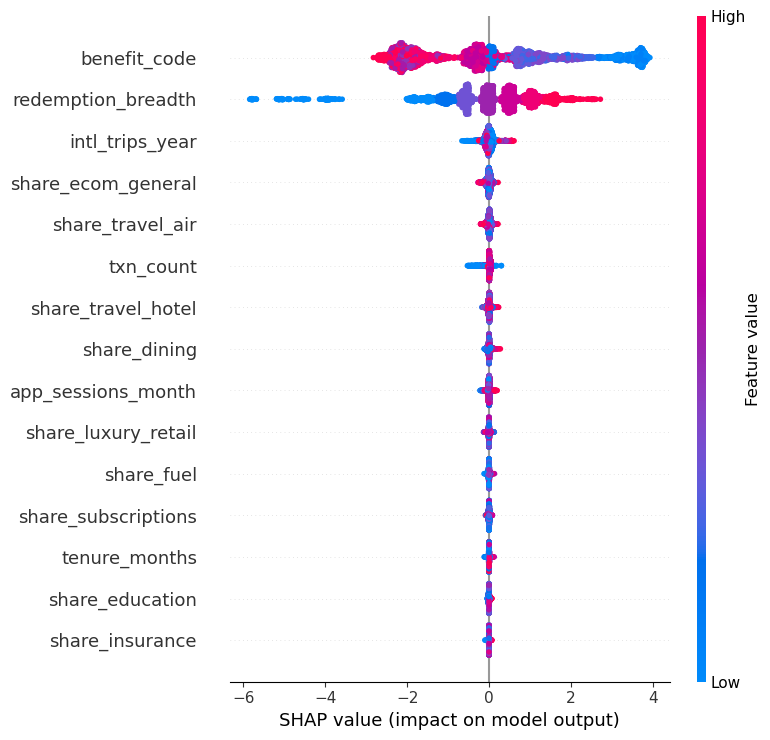

In [6]:
"""
Phase 3 — Propensity scoring with LightGBM
Reads: gap_causes.csv, amex_benefit_utilisation_v2.xlsx, amex_transactions_v2.csv
Writes: propensity_scores.csv, shap_summary.png
"""

import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import shap
import matplotlib.pyplot as plt

# ── Load ──
xl = pd.ExcelFile("amex_benefit_utilisation_v2.xlsx")
customers = pd.read_excel(xl, "customers")
redemptions = pd.read_excel(xl, "redemptions")
registry = pd.read_excel(xl, "benefit_registry")
txns = pd.read_csv("amex_transactions_v2.csv")
gap_causes = pd.read_csv("gap_causes.csv")

monetary = registry[registry["face_value_inr"] > 0]["benefit_id"].tolist()

# ── Feature engineering (observable signals only — NO latent traits) ──
cust_spend = txns.groupby("customer_id")["amount"].sum().rename("total_spend")

cat_spend = txns.pivot_table(
    index="customer_id", columns="mcc_category",
    values="amount", aggfunc="sum", fill_value=0
)
# Convert to shares
cat_shares = cat_spend.div(cat_spend.sum(axis=1), axis=0).add_prefix("share_")

channel_share = (
    txns[txns["channel"] == "ecom"]
    .groupby("customer_id")["amount"].sum() / cust_spend
).fillna(0).rename("ecom_share_actual")

txn_count = txns.groupby("customer_id").size().rename("txn_count")
avg_ticket = txns.groupby("customer_id")["amount"].mean().rename("avg_ticket")

# Redemption breadth
breadth = (
    redemptions.groupby("customer_id")["benefit_id"].nunique()
    .rename("redemption_breadth")
)

# Merge all features
features = customers[["customer_id", "city", "age", "tenure_months",
                       "annual_spend", "app_sessions_month",
                       "intl_trips_year"]].copy()
features = features.merge(cat_shares, left_on="customer_id", right_index=True, how="left")
features = features.merge(channel_share, left_on="customer_id", right_index=True, how="left")
features = features.merge(txn_count, left_on="customer_id", right_index=True, how="left")
features = features.merge(avg_ticket, left_on="customer_id", right_index=True, how="left")
features = features.merge(breadth, left_on="customer_id", right_index=True, how="left")
features["redemption_breadth"] = features["redemption_breadth"].fillna(0)

# Encode city
features["city"] = features["city"].astype("category").cat.codes

# ── Build training rows: one row per (customer, benefit) ──
# Label = 1 if redeemed, 0 if not
redeemed = set(zip(redemptions["customer_id"], redemptions["benefit_id"]))

train_rows = []
for bid in monetary:
    for cid in customers["customer_id"]:
        train_rows.append((cid, bid, 1 if (cid, bid) in redeemed else 0))

train_df = pd.DataFrame(train_rows, columns=["customer_id", "benefit_id", "label"])

# Add benefit_id as a feature (encoded)
train_df["benefit_code"] = train_df["benefit_id"].astype("category").cat.codes

# Merge customer features
train_df = train_df.merge(features, on="customer_id")

feature_cols = [c for c in train_df.columns
                if c not in ("customer_id", "benefit_id", "label")]

X = train_df[feature_cols].values
y = train_df["label"].values

# ── Train with 3-fold CV ──
print("Training LightGBM propensity model...")
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
aucs = []
models = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
    dtrain = lgb.Dataset(X[tr_idx], y[tr_idx])
    dval = lgb.Dataset(X[va_idx], y[va_idx], reference=dtrain)

    params = {
        "objective": "binary",
        "metric": "auc",
        "learning_rate": 0.05,
        "num_leaves": 63,
        "min_child_samples": 100,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "verbose": -1,
    }

    model = lgb.train(
        params, dtrain,
        num_boost_round=500,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(30), lgb.log_evaluation(0)],
    )
    preds = model.predict(X[va_idx])
    auc = roc_auc_score(y[va_idx], preds)
    aucs.append(auc)
    models.append(model)
    print(f"  Fold {fold+1} AUC: {auc:.4f}")

print(f"  Mean AUC: {np.mean(aucs):.4f}")

# ── Score all pairs with best model ──
best = models[np.argmax(aucs)]
train_df["propensity"] = best.predict(X)

# ── SHAP ──
print("Computing SHAP values...")
explainer = shap.TreeExplainer(best)
# Sample 5000 rows for SHAP (full set too slow)
sample_idx = np.random.choice(len(X), 5000, replace=False)
shap_values = explainer.shap_values(X[sample_idx])

# For binary: shap_values is [neg_class, pos_class], take pos
if isinstance(shap_values, list):
    sv = shap_values[1]
else:
    sv = shap_values

plt.figure(figsize=(10, 8))
shap.summary_plot(sv, X[sample_idx],
                  feature_names=feature_cols, show=False, max_display=15)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150)
print("Saved shap_summary.png")

# ── Write scores ──
output = train_df[["customer_id", "benefit_id", "label", "propensity"]].copy()
output.to_csv("propensity_scores.csv", index=False)
print(f"Wrote propensity_scores.csv ({len(output)} rows)")

# ── Quick sanity ──
print("\nMean propensity by cause:")
cause_map = gap_causes[["customer_id", "benefit_id", "cause"]].drop_duplicates()
merged = output.merge(cause_map, on=["customer_id", "benefit_id"], how="left")
merged["cause"] = merged["cause"].fillna("redeemed")
print(merged.groupby("cause")["propensity"].mean().sort_values(ascending=False).to_string())

In [7]:
"""
Phase 4 — Knapsack: pick the nudge set that maximizes net value
           subject to ≤₹20K incremental cost per member.
Reads: propensity_scores.csv, gap_causes.csv,
       amex_benefit_utilisation_v2.xlsx
Writes: nudge_recommendations.csv, roi_summary.csv
"""

import pandas as pd
import numpy as np

# ── Load ──
propensity = pd.read_csv("propensity_scores.csv")
gap_causes = pd.read_csv("gap_causes.csv")
xl = pd.ExcelFile("amex_benefit_utilisation_v2.xlsx")
registry = pd.read_excel(xl, "benefit_registry")
customers = pd.read_excel(xl, "customers")

BUDGET = 20_000  # ₹20K per card per year

# ── Build cost table per benefit ──
# cost_class determines marginal cost to issuer of a redemption
cost_map = dict(zip(registry["benefit_id"], registry["cost_class"]))
face_map = dict(zip(registry["benefit_id"], registry["face_value_inr"]))

def marginal_cost(benefit_id, face_value):
    """Issuer's cost if member redeems this benefit."""
    cc = cost_map.get(benefit_id, "zero_marginal")
    if cc == "zero_marginal":
        return 0                          # insurance, protection — no marginal cost
    elif cc == "non_monetary":
        return 0
    elif cc == "partner_funded":
        return face_value * 0.10          # partner pays 90%
    elif cc == "spend_linked":
        return face_value * 0.30          # issuer rebate ~30% of face
    elif cc == "variable":
        return face_value * 0.50          # issuer pays ~50% (lounge, golf, transfers)
    return face_value * 0.50

# ── Merge propensity + gap causes ──
# Only consider non-redeemed pairs with addressable causes
addressable = gap_causes[gap_causes["cause"].isin(["timing", "awareness", "friction"])].copy()
merged = addressable.merge(
    propensity[["customer_id", "benefit_id", "propensity"]],
    on=["customer_id", "benefit_id"],
    how="left"
)
merged["face_value"] = merged["benefit_id"].map(face_map)
merged["cost_if_redeemed"] = merged.apply(
    lambda r: marginal_cost(r["benefit_id"], r["face_value"]), axis=1
)

# ── Net value of nudging = expected_recovered_value - expected_cost ──
# expected_recovered = gap_value × propensity (how much gap we close)
# expected_cost = cost_if_redeemed × propensity (expected cost to issuer)
# nudge_cost = fixed ₹50 per nudge (SMS/push/email cost)
NUDGE_COST = 50

merged["expected_recovery"] = merged["gap_value"] * merged["propensity"]
merged["expected_cost"] = merged["cost_if_redeemed"] * merged["propensity"] + NUDGE_COST
merged["net_value"] = merged["expected_recovery"] - merged["expected_cost"]
merged["value_per_rupee"] = merged["net_value"] / merged["expected_cost"].clip(lower=1)

# ── Greedy knapsack per member ──
recommendations = []

for cid, group in merged.groupby("customer_id"):
    # Sort by value_per_rupee descending (best bang for buck first)
    ranked = group.sort_values("value_per_rupee", ascending=False)

    budget_remaining = BUDGET
    member_recs = []

    for _, row in ranked.iterrows():
        if row["net_value"] <= 0:
            continue  # skip negative-ROI nudges
        cost = row["expected_cost"]
        if cost <= budget_remaining:
            budget_remaining -= cost
            member_recs.append({
                "customer_id": cid,
                "benefit_id": row["benefit_id"],
                "cause": row["cause"],
                "propensity": round(row["propensity"], 4),
                "gap_value": round(row["gap_value"], 0),
                "expected_recovery": round(row["expected_recovery"], 0),
                "expected_cost": round(row["expected_cost"], 0),
                "net_value": round(row["net_value"], 0),
                "value_per_rupee": round(row["value_per_rupee"], 2),
            })

    recommendations.extend(member_recs)

rec_df = pd.DataFrame(recommendations)

# ── ROI Summary ──
if len(rec_df) > 0:
    total_recovery = rec_df["expected_recovery"].sum()
    total_cost = rec_df["expected_cost"].sum()
    total_net = rec_df["net_value"].sum()
    n_members = rec_df["customer_id"].nunique()
    n_nudges = len(rec_df)

    print("\n========== ROI SUMMARY ==========")
    print(f"  Members nudged:         {n_members:,}")
    print(f"  Total nudges:           {n_nudges:,}")
    print(f"  Avg nudges/member:      {n_nudges/n_members:.1f}")
    print(f"  Total expected recovery: Rs {total_recovery/1e7:,.1f} Cr")
    print(f"  Total expected cost:     Rs {total_cost/1e7:,.1f} Cr")
    print(f"  Total net value:         Rs {total_net/1e7:,.1f} Cr")
    print(f"  ROI:                     {total_net/total_cost*100:.0f}%")
    print(f"  Avg cost/member:         Rs {total_cost/n_members:,.0f}")
    print(f"  Avg net value/member:    Rs {total_net/n_members:,.0f}")

    # By cause
    print("\n========== NET VALUE BY CAUSE ==========")
    cause_summary = rec_df.groupby("cause").agg(
        total_net=("net_value", "sum"),
        count=("net_value", "count"),
        avg_propensity=("propensity", "mean")
    )
    cause_summary["total_net_cr"] = cause_summary["total_net"] / 1e7
    print(cause_summary[["total_net_cr", "count", "avg_propensity"]].to_string())

    # By benefit
    print("\n========== TOP 10 BENEFITS BY NET VALUE ==========")
    benefit_summary = rec_df.groupby("benefit_id").agg(
        total_net=("net_value", "sum"),
        count=("net_value", "count"),
        avg_propensity=("propensity", "mean")
    ).sort_values("total_net", ascending=False).head(10)
    benefit_summary["total_net_cr"] = benefit_summary["total_net"] / 1e7
    print(benefit_summary[["total_net_cr", "count", "avg_propensity"]].to_string())

# ── Write ──
rec_df.to_csv("nudge_recommendations.csv", index=False)
print(f"\nWrote nudge_recommendations.csv ({len(rec_df)} rows)")


========== ROI SUMMARY ==========
  Members nudged:         39,593
  Total nudges:           337,177
  Avg nudges/member:      8.5
  Total expected recovery: Rs 145.4 Cr
  Total expected cost:     Rs 18.0 Cr
  Total net value:         Rs 127.3 Cr
  ROI:                     706%
  Avg cost/member:         Rs 4,555
  Avg net value/member:    Rs 32,164

========== NET VALUE BY CAUSE ==========
           total_net_cr   count  avg_propensity
cause                                          
awareness     22.694402  140100        0.257262
friction      48.753304   39718        0.254545
timing        55.898993  157359        0.220678

========== TOP 10 BENEFITS BY NET VALUE ==========
            total_net_cr  count  avg_propensity
benefit_id                                     
B06            99.152115  34063        0.564907
B03             5.204660  31975        0.246991
B04             4.991188  16357        0.499908
B01             3.726227   3549        0.685183
B11             3.292404 

In [15]:
# """
# Phase 6 — LLM Reasoning Layer
# Reads: gap_causes.csv, propensity_scores.csv, nudge_recommendations.csv,
#        amex_benefit_utilisation_v2.xlsx
# Writes: llm_diagnoses.csv
# """

# import pandas as pd
# import numpy as np
# import json
# import time

# # ── Load ──
# gap = pd.read_csv("gap_causes.csv")
# propensity = pd.read_csv("propensity_scores.csv")
# recs = pd.read_csv("nudge_recommendations.csv")
# xl = pd.ExcelFile("amex_benefit_utilisation_v2.xlsx")
# customers = pd.read_excel(xl, "customers")
# registry = pd.read_excel(xl, "benefit_registry")

# benefit_name_map = dict(zip(registry["benefit_id"], registry["name"]))

# import google.generativeai as genai
# genai.configure(api_key="AQ.Ab8RN6LAJQf0VscaoWIvtWBaRGTjcXVVdEqDJPNueXWwmFAE9Q")
# model = genai.GenerativeModel("gemini-3.5-flash-lite")  # free tier, fast

# SYSTEM_PROMPT = """You are an assistant to an American Express relationship manager in India.
# You will receive structured data about a single Platinum Charge Card member.
# Your job is to produce a concise 3-4 sentence diagnostic paragraph.

# Rules:
# - Use ONLY the numbers provided in the JSON. Never invent or estimate figures.
# - Structure: (1) What the gap looks like. (2) Root cause diagnosis. (3) Recommended action. (4) Expected outcome.
# - Tone: analytical, professional — what an RM would say in a portfolio review meeting.
# - Do not use bullet points. Plain paragraph only.
# - Do not use phrases like "based on the data" or "according to the JSON"."""


# def build_member_payload(customer_id):
#     # Customer profile
#     cust = customers[customers["customer_id"] == customer_id].iloc[0]

#     # Gap summary
#     member_gap = gap[gap["customer_id"] == customer_id]
#     total_gap = member_gap["gap_value"].sum()
#     cause_breakdown = (
#         member_gap.groupby("cause")["gap_value"]
#         .sum()
#         .sort_values(ascending=False)
#         .head(3)
#         .to_dict()
#     )
#     cause_breakdown = {k: round(v, 0) for k, v in cause_breakdown.items()}

#     # Top 3 benefits by propensity (non-redeemed)
#     member_prop = propensity[
#         propensity["customer_id"] == customer_id
#     ].sort_values("propensity", ascending=False).head(3)
    
#     top_benefits = []
#     for _, row in member_prop.iterrows():
#         top_benefits.append({
#             "benefit": benefit_name_map.get(row["benefit_id"], row["benefit_id"]),
#             "propensity": round(row["propensity"], 2)
#         })

#     # Nudge recommendations
#     member_recs = recs[recs["customer_id"] == customer_id].sort_values(
#         "net_value", ascending=False
#     ).head(3)

#     nudges = []
#     for _, row in member_recs.iterrows():
#         nudges.append({
#             "benefit": benefit_name_map.get(row["benefit_id"], row["benefit_id"]),
#             "cause": row["cause"],
#             "expected_recovery_inr": int(row["expected_recovery"]),
#             "net_value_inr": int(row["net_value"])
#         })

#     payload = {
#         "customer_id": str(customer_id),
#         "archetype": cust["archetype"],
#         "tenure_months": int(cust["tenure_months"]),
#         "annual_spend_inr": int(cust["annual_spend"]),
#         "total_benefit_gap_inr": int(total_gap),
#         "gap_by_cause_inr": cause_breakdown,
#         "top_benefits_by_propensity": top_benefits,
#         "recommended_nudges": nudges
#     }
#     return payload


# def get_diagnosis(payload):
#     prompt = f"{SYSTEM_PROMPT}\n\nMember data:\n{json.dumps(payload, indent=2)}\n\nWrite the diagnostic paragraph."
#     response = model.generate_content(prompt)
#     return response.text


# # ── Run on sample of 200 members ──
# SAMPLE_SIZE = 200  # change to len(customers) for full run

# sample_ids = customers["customer_id"].sample(SAMPLE_SIZE, random_state=42).tolist()

# results = []
# failed = []

# for i, cid in enumerate(sample_ids):
#     try:
#         payload = build_member_payload(cid)
#         diagnosis = get_diagnosis(payload)
#         results.append({
#             "customer_id": cid,
#             "archetype": payload["archetype"],
#             "top_cause": max(payload["gap_by_cause_inr"], key=payload["gap_by_cause_inr"].get) if payload["gap_by_cause_inr"] else "unknown",
#             "total_gap_inr": payload["total_benefit_gap_inr"],
#             "diagnosis_text": diagnosis
#         })
#         if (i + 1) % 20 == 0:
#             print(f"  [{i+1}/{SAMPLE_SIZE}] done...")
#         time.sleep(0.3)  # avoid rate limit

#     except Exception as e:
#         failed.append({"customer_id": cid, "error": str(e)})
#         print(f"  [FAILED] {cid}: {e}")

# # ── Write output ──
# out = pd.DataFrame(results)
# out.to_csv("llm_diagnoses.csv", index=False)
# print(f"\nWrote llm_diagnoses.csv ({len(out)} rows)")
# if failed:
#     print(f"Failed: {len(failed)} members")

# # ── Preview — pick 3 contrasting archetypes for your slide ──
# print("\n========== SAMPLE DIAGNOSES ==========")
# for archetype in ["Dormant Premium", "Global Traveller", "Digital Affluent"]:
#     row = out[out["archetype"] == archetype]
#     if len(row) == 0:
#         continue
#     row = row.iloc[0]
#     print(f"\n[{archetype}] — Gap: ₹{row['total_gap_inr']:,.0f}")
#     print(row["diagnosis_text"])
#     print("-" * 60)

  [FAILED] C19464: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 15, model: gemini-3.5-flash-lite
Please retry in 2.452891151s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://ai.google.dev/gemini-api/docs/rate-limits"
}
, violations {
  quota_metric: "generativelanguage.googleapis.com/generate_content_free_tier_requests"
  quota_id: "GenerateRequestsPerMinutePerProjectPerModel-FreeTier"
  quota_dimensions {
    key: "model"
    value: "gemini-3.5-flash-lite"
  }
  quota_dimensions {
    key: "location"
    value: "global"
  }
  quota_value: 15
}
, retry_delay {
  seconds: 2
}
]
  [FAILED] C26284: 429 You exceeded your current quota, please check your plan 

In [16]:
"""
Phase 6 — LLM Reasoning Layer
Reads: gap_causes.csv, propensity_scores.csv, nudge_recommendations.csv,
amex_benefit_utilisation_v2.xlsx
Writes: llm_diagnoses.csv
"""

import pandas as pd
import numpy as np
import json
import time

# ── Load ──

gap = pd.read_csv("gap_causes.csv")
propensity = pd.read_csv("propensity_scores.csv")
recs = pd.read_csv("nudge_recommendations.csv")

xl = pd.ExcelFile("amex_benefit_utilisation_v2.xlsx")
customers = pd.read_excel(xl, "customers")
registry = pd.read_excel(xl, "benefit_registry")

benefit_name_map = dict(
    zip(registry["benefit_id"], registry["name"])
)


# ── Gemini Setup ──

import google.generativeai as genai

genai.configure(
    api_key="AQ.Ab8RN6LAJQf0VscaoWIvtWBaRGTjcXVVdEqDJPNueXWwmFAE9Q"
)

model = genai.GenerativeModel(
    "gemini-3.5-flash-lite"
)


# ── System Prompt ──

SYSTEM_PROMPT = """
You are an assistant to an American Express relationship manager in India.

You will receive structured data about a single Platinum Charge Card member.

Your job is to produce a concise 3-4 sentence diagnostic paragraph.

Rules:

- Use ONLY the numbers provided in the JSON. Never invent or estimate figures.
- Structure:
  (1) What the gap looks like.
  (2) Root cause diagnosis.
  (3) Recommended action.
  (4) Expected outcome.
- Tone: analytical, professional — what an RM would say in a portfolio review meeting.
- Do not use bullet points.
- Plain paragraph only.
- Do not use phrases like "based on the data" or "according to the JSON".
"""


# ── Build Member Payload ──

def build_member_payload(customer_id):

    # Customer profile
    customer_rows = customers[
        customers["customer_id"] == customer_id
    ]

    if customer_rows.empty:
        raise ValueError(
            f"Customer {customer_id} not found in customers data."
        )

    cust = customer_rows.iloc[0]


    # Gap summary
    member_gap = gap[
        gap["customer_id"] == customer_id
    ]

    total_gap = member_gap["gap_value"].sum()

    cause_breakdown = (
        member_gap
        .groupby("cause")["gap_value"]
        .sum()
        .sort_values(ascending=False)
        .head(3)
        .to_dict()
    )

    cause_breakdown = {
        str(k): round(float(v), 0)
        for k, v in cause_breakdown.items()
    }


    # Top 3 benefits by propensity
    member_prop = (
        propensity[
            propensity["customer_id"] == customer_id
        ]
        .sort_values(
            "propensity",
            ascending=False
        )
        .head(3)
    )

    top_benefits = []

    for _, row in member_prop.iterrows():

        benefit_id = row["benefit_id"]

        top_benefits.append({
            "benefit": benefit_name_map.get(
                benefit_id,
                benefit_id
            ),
            "propensity": round(
                float(row["propensity"]),
                2
            )
        })


    # Nudge recommendations
    member_recs = (
        recs[
            recs["customer_id"] == customer_id
        ]
        .sort_values(
            "net_value",
            ascending=False
        )
        .head(3)
    )

    nudges = []

    for _, row in member_recs.iterrows():

        benefit_id = row["benefit_id"]

        nudges.append({
            "benefit": benefit_name_map.get(
                benefit_id,
                benefit_id
            ),
            "cause": str(row["cause"]),
            "expected_recovery_inr": int(
                row["expected_recovery"]
            ),
            "net_value_inr": int(
                row["net_value"]
            )
        })


    # Final payload
    payload = {
        "customer_id": str(customer_id),

        "archetype": str(
            cust["archetype"]
        ),

        "tenure_months": int(
            cust["tenure_months"]
        ),

        "annual_spend_inr": int(
            cust["annual_spend"]
        ),

        "total_benefit_gap_inr": int(
            total_gap
        ),

        "gap_by_cause_inr": cause_breakdown,

        "top_benefits_by_propensity": top_benefits,

        "recommended_nudges": nudges
    }

    return payload


# ── Gemini Diagnosis ──

def get_diagnosis(payload):

    prompt = (
        f"{SYSTEM_PROMPT}\n\n"
        f"Member data:\n"
        f"{json.dumps(payload, indent=2)}\n\n"
        f"Write the diagnostic paragraph."
    )


    # Retry settings
    max_retries = 5

    for attempt in range(max_retries):

        try:

            response = model.generate_content(
                prompt
            )

            if response.text:
                return response.text.strip()

            raise ValueError(
                "Gemini returned an empty response."
            )


        except Exception as e:

            error_message = str(e)

            # Handle Gemini 429 rate-limit errors
            if "429" in error_message or "quota" in error_message.lower():

                if attempt == max_retries - 1:
                    raise

                # Exponential backoff
                wait_time = min(
                    60,
                    5 * (2 ** attempt)
                )

                print(
                    f"    Rate limit reached. "
                    f"Retrying in {wait_time} seconds..."
                )

                time.sleep(wait_time)

            else:
                raise


# ── Run on sample of 200 members ──

SAMPLE_SIZE = 200
# Change to len(customers) for full run


# Prevent error if dataset has fewer than 200 customers
sample_size = min(
    SAMPLE_SIZE,
    len(customers)
)

sample_ids = (
    customers["customer_id"]
    .sample(
        sample_size,
        random_state=42
    )
    .tolist()
)


results = []
failed = []


print(
    f"\nRunning LLM diagnosis for "
    f"{sample_size} members..."
)


# ── Process Members ──

for i, cid in enumerate(
    sample_ids,
    start=1
):

    try:

        payload = build_member_payload(
            cid
        )

        diagnosis = get_diagnosis(
            payload
        )


        results.append({
            "customer_id": cid,

            "archetype": payload[
                "archetype"
            ],

            "top_cause": (
                max(
                    payload[
                        "gap_by_cause_inr"
                    ],
                    key=payload[
                        "gap_by_cause_inr"
                    ].get
                )
                if payload[
                    "gap_by_cause_inr"
                ]
                else "unknown"
            ),

            "total_gap_inr": payload[
                "total_benefit_gap_inr"
            ],

            "diagnosis_text": diagnosis
        })


        # Progress
        print(
            f"  [{i}/{sample_size}] "
            f"{cid} done..."
        )


        # IMPORTANT:
        # Wait between API calls to reduce
        # rate-limit problems.
        #
        # 0.3 seconds is too aggressive for
        # a free-tier API.

        if i < sample_size:
            time.sleep(5)


    except Exception as e:

        failed.append({
            "customer_id": cid,
            "error": str(e)
        })

        print(
            f"  [FAILED] {cid}: {e}"
        )


# ── Write Output ──

out = pd.DataFrame(
    results
)

out.to_csv(
    "llm_diagnoses.csv",
    index=False
)


print(
    f"\nWrote llm_diagnoses.csv "
    f"({len(out)} rows)"
)


if failed:

    print(
        f"Failed: {len(failed)} members"
    )


    # Save failed records too
    failed_df = pd.DataFrame(
        failed
    )

    failed_df.to_csv(
        "llm_diagnoses_failed.csv",
        index=False
    )

    print(
        "Failed records written to "
        "llm_diagnoses_failed.csv"
    )


# ── Preview — Pick 3 Contrasting Archetypes ──

print(
    "\n========== SAMPLE DIAGNOSES =========="
)


for archetype in [
    "Dormant Premium",
    "Global Traveller",
    "Digital Affluent"
]:

    row = out[
        out["archetype"] == archetype
    ]


    if len(row) == 0:
        continue


    row = row.iloc[0]


    print(
        f"\n[{archetype}] — "
        f"Gap: ₹"
        f"{row['total_gap_inr']:,.0f}"
    )

    print(
        row["diagnosis_text"]
    )

    print(
        "-" * 60
    )


Running LLM diagnosis for 200 members...
  [1/200] C32824 done...
  [2/200] C16299 done...
  [3/200] C28506 done...
  [4/200] C06690 done...
  [5/200] C26894 done...
  [6/200] C36573 done...
  [7/200] C12336 done...
  [8/200] C29592 done...
  [9/200] C18949 done...
  [10/200] C31068 done...
  [11/200] C22242 done...
  [12/200] C13788 done...
  [13/200] C05129 done...
  [14/200] C09126 done...
  [15/200] C35042 done...
  [16/200] C03511 done...
  [17/200] C16442 done...
  [18/200] C19464 done...
  [19/200] C26284 done...
  [20/200] C36217 done...
  [21/200] C17408 done...
  [22/200] C10920 done...
  [23/200] C30867 done...
  [24/200] C34437 done...
  [25/200] C12702 done...
  [26/200] C35677 done...
  [27/200] C34090 done...
  [28/200] C21262 done...
  [29/200] C26174 done...
  [30/200] C28284 done...
  [31/200] C37267 done...
  [32/200] C32507 done...
  [33/200] C33382 done...
  [34/200] C39381 done...
  [35/200] C20846 done...
  [36/200] C00253 done...
  [37/200] C35120 done...
  [38

In [19]:
"""
Phase 5 — Nudge Copy Generation
Reads: nudge_recommendations.csv, amex_benefit_utilisation_v2.xlsx
Writes: nudge_copy.csv
"""

import pandas as pd
import json
import time
import google.generativeai as genai

# ── Load ──
recs = pd.read_csv("nudge_recommendations.csv")
xl = pd.ExcelFile("amex_benefit_utilisation_v2.xlsx")
customers = pd.read_excel(xl, "customers")
registry = pd.read_excel(xl, "benefit_registry")

benefit_name_map = dict(zip(registry["benefit_id"], registry["name"]))

# ── Gemini Setup ──
genai.configure(api_key="AQ.Ab8RN6LAJQf0VscaoWIvtWBaRGTjcXVVdEqDJPNueXWwmFAE9Q")
model = genai.GenerativeModel("gemini-3.5-flash-lite")

# ── System Prompt ──
SYSTEM_PROMPT = """
You are a copywriter for American Express India's Platinum Charge Card team.

You will receive details about a card member and their top recommended benefit.

Write a single personalized push notification (max 2 sentences, under 160 characters total).

Rules:
- Warm but premium tone — not salesy, not generic
- Reference the specific benefit by name
- Do not mention rupee amounts or percentages
- Do not start with "Hi" or "Dear"
- No emojis
- Output only the notification text, nothing else
"""

def build_nudge_payload(customer_id):
    cust = customers[customers["customer_id"] == customer_id].iloc[0]

    # Top nudge by net value for this member
    top_nudge = (
        recs[recs["customer_id"] == customer_id]
        .sort_values("net_value", ascending=False)
        .iloc[0]
    )

    return {
        "customer_id": str(customer_id),
        "archetype": str(cust["archetype"]),
        "tenure_months": int(cust["tenure_months"]),
        "benefit": benefit_name_map.get(top_nudge["benefit_id"], top_nudge["benefit_id"]),
        "cause": str(top_nudge["cause"]),  # timing / awareness / friction
    }


def get_nudge_copy(payload):
    prompt = (
        f"{SYSTEM_PROMPT}\n\n"
        f"Member data:\n"
        f"{json.dumps(payload, indent=2)}\n\n"
        f"Write the push notification."
    )

    max_retries = 5

    for attempt in range(max_retries):
        try:
            response = model.generate_content(prompt)
            if response.text:
                return response.text.strip()
            raise ValueError("Empty response from Gemini.")

        except Exception as e:
            error_message = str(e)
            if "429" in error_message or "quota" in error_message.lower():
                if attempt == max_retries - 1:
                    raise
                wait_time = min(60, 5 * (2 ** attempt))
                print(f"    Rate limit. Retrying in {wait_time}s...")
                time.sleep(wait_time)
            else:
                raise


# ── Run on same 200 members as Phase 6 ──
SAMPLE_SIZE = 200

# Use members who have at least one recommendation
eligible_ids = recs["customer_id"].unique()
sample_ids = (
    pd.Series(eligible_ids)
    .sample(min(SAMPLE_SIZE, len(eligible_ids)), random_state=42)
    .tolist()
)

results = []
failed = []

print(f"\nGenerating nudge copy for {len(sample_ids)} members...")

for i, cid in enumerate(sample_ids, start=1):
    try:
        payload = build_nudge_payload(cid)
        copy = get_nudge_copy(payload)

        results.append({
            "customer_id": cid,
            "archetype": payload["archetype"],
            "benefit": payload["benefit"],
            "cause": payload["cause"],
            "nudge_copy": copy
        })

        print(f"  [{i}/{len(sample_ids)}] {cid} done...")

        if i < len(sample_ids):
            time.sleep(5)

    except Exception as e:
        failed.append({"customer_id": cid, "error": str(e)})
        print(f"  [FAILED] {cid}: {e}")

# ── Write Output ──
out = pd.DataFrame(results)
out.to_csv("nudge_copy.csv", index=False)
print(f"\nWrote nudge_copy.csv ({len(out)} rows)")

if failed:
    pd.DataFrame(failed).to_csv("nudge_copy_failed.csv", index=False)
    print(f"Failed: {len(failed)} — saved to nudge_copy_failed.csv")

# ── Preview — one per archetype ──
print("\n========== SAMPLE NUDGE COPY ==========")
for archetype in ["Dormant Premium", "Global Traveller", "Digital Affluent", "Business Owner", "Domestic Executive"]:
    row = out[out["archetype"] == archetype]
    if len(row) == 0:
        continue
    row = row.iloc[0]
    print(f"\n[{archetype}] — {row['benefit']} ({row['cause']})")
    print(f"  {row['nudge_copy']}")
    print("-" * 60)


Generating nudge copy for 200 members...
  [1/200] C14101 done...
  [2/200] C29091 done...
  [3/200] C23483 done...
  [4/200] C18730 done...
  [5/200] C28084 done...
  [6/200] C13060 done...
  [7/200] C29538 done...
  [8/200] C14851 done...
  [9/200] C24763 done...
  [10/200] C28190 done...
  [11/200] C07541 done...
  [12/200] C25464 done...
  [13/200] C16423 done...
  [14/200] C01757 done...
  [15/200] C32838 done...
  [16/200] C06171 done...
  [17/200] C29024 done...
  [18/200] C08201 done...
  [19/200] C15268 done...
  [20/200] C22868 done...
  [21/200] C16577 done...
  [22/200] C34266 done...
  [23/200] C00935 done...
  [24/200] C02303 done...
  [25/200] C23939 done...
  [26/200] C31390 done...
  [27/200] C03454 done...
  [28/200] C18447 done...
  [29/200] C29922 done...
  [30/200] C32532 done...
  [31/200] C12208 done...
  [32/200] C31867 done...
  [33/200] C13012 done...
  [34/200] C06111 done...
  [35/200] C10947 done...
  [36/200] C02258 done...
  [37/200] C22581 done...
  [38